What is regression?
Regression predicts a continuous numerical value from input features.

Examples:
- Predict house prices.
- Estimate monthly sales.
- Forecast electricity consumption.
- Predict delivery time.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# House size in sq ft
X = np.array([
    400, 500, 550, 650, 750,
    800, 900, 1000, 1050, 1150,
    1250, 1300, 1400, 1500, 1550,
    1650, 1750, 1800, 1900, 2000,
    2100, 2150, 2250, 2350, 2400,
    2500, 2600, 2650, 2750, 2850,
    2900, 3000, 3100, 3150, 3250,
    3350, 3400, 3500
])

# House price in lakhs (with realistic data noise)
y = np.array([
    20, 20, 23, 29, 27,
    30, 39, 39, 39, 45,
    45, 48, 54, 50, 54,
    61, 63, 70, 69, 71,
    83, 81, 85, 84, 89,
    95, 94, 102, 102, 106,
    108, 119, 117, 117, 125,
    122, 130, 127
])

df = pd.DataFrame({
    "Size": X,
    "Price": y
})

df.head()

,Size,Price
0,400,20
1,500,20
2,550,23
3,650,29
4,750,27


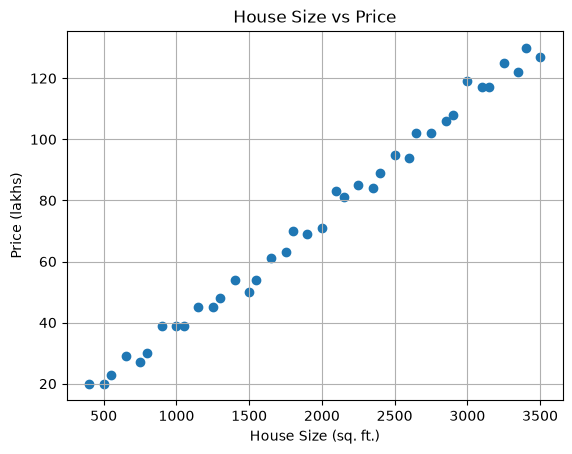

In [7]:
plt.scatter(X, y)
plt.xlabel("House Size (sq. ft.)")
plt.ylabel("Price (lakhs)")
plt.title("House Size vs Price")
plt.grid(True)
plt.show()

In [8]:
from sklearn.linear_model import LinearRegression

# Scikit-learn expects X to have shape (samples, features)
X_2d = X.reshape(-1, 1)

model = LinearRegression()
model.fit(X_2d, y)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 0.03685190934492394
Intercept: 1.3493030931877996


In [9]:
print(
    f"Price = {model.coef_[0]:.4f} * Size "
    f"+ {model.intercept_:.4f}"
)

Price = 0.0369 * Size + 1.3493


In [10]:
new_houses = np.array([
    [900],
    [1400],
    [2100]
])

predictions = model.predict(new_houses)

for size, price in zip(new_houses.flatten(), predictions):
    print(f"Size: {size} sq. ft. -> Predicted price: {price:.2f} lakhs")

Size: 900 sq. ft. -> Predicted price: 34.52 lakhs
Size: 1400 sq. ft. -> Predicted price: 52.94 lakhs
Size: 2100 sq. ft. -> Predicted price: 78.74 lakhs


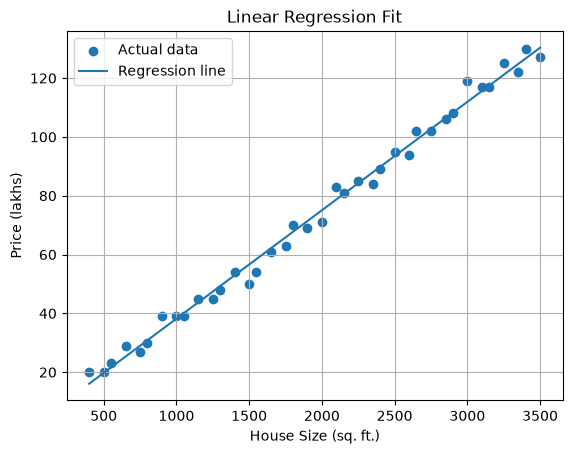

In [11]:
y_pred = model.predict(X_2d)

plt.scatter(X, y, label="Actual data")

plt.plot(
    X,
    y_pred,
    label="Regression line"
)

plt.xlabel("House Size (sq. ft.)")
plt.ylabel("Price (lakhs)")
plt.title("Linear Regression Fit")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  2.359
MSE:  8.503
RMSE: 2.916
R²:   0.993
